# **`Milestone II`**

# C1: Comprehension data exploration

---



In [2]:
#read the uploaded cleand csv files
import pandas as pd

crop = pd.read_csv("data/M2C1_cleaned_crop_yield.csv")
rain = pd.read_csv("data/M2C1_cleaned_rainfall.csv")
fert = pd.read_csv("data/M2C1_cleaned_fertilizer.csv")
land = pd.read_csv("data/M2C1_cleaned_land_area.csv")
temp = pd.read_csv("data/M2C1_cleaned_temperature.csv")

In [3]:
#Check the structure of the fields to see if their is no error

datasets = {
    "crop": crop,
    "rain": rain,
    "fert": fert,
    "land": land,
    "temp": temp
}

for name, df in datasets.items():
    print(f"\n===== {name.upper()} =====")
    print(df.head())
    print("\nColumns:", df.columns.tolist())
    print("Shape:", df.shape)


===== CROP =====
   Country  Year  Crop_Yield Element
0  Algeria  2000       975.4   Yield
1  Algeria  2001       934.0   Yield
2  Algeria  2002      1164.8   Yield
3  Algeria  2003      1052.4   Yield
4  Algeria  2004      1247.3   Yield

Columns: ['Country', 'Year', 'Crop_Yield', 'Element']
Shape: (47982, 4)

===== RAIN =====
        Country Country Code  Year  Rainfall
0        Angola          AGO  2000    1010.0
1       Burundi          BDI  2000    1218.0
2         Benin          BEN  2000    1039.0
3  Burkina Faso          BFA  2000     748.0
4      Botswana          BWA  2000     416.0

Columns: ['Country', 'Country Code', 'Year', 'Rainfall']
Shape: (1195, 4)

===== FERT =====
        Country Country Code  Year  Fertilizer_Usage
0        Angola          AGO  2000          0.466667
1       Burundi          BDI  2000          3.645833
2         Benin          BEN  2000         14.789916
3  Burkina Faso          BFA  2000          6.600938
4      Botswana          BWA  2000       

In [4]:
#Check missing values

for name, df in datasets.items():
    print(f"\n===== MISSING VALUES IN {name.upper()} =====")
    print(df.isnull().sum())


===== MISSING VALUES IN CROP =====
Country       0
Year          0
Crop_Yield    0
Element       0
dtype: int64

===== MISSING VALUES IN RAIN =====
Country         0
Country Code    0
Year            0
Rainfall        0
dtype: int64

===== MISSING VALUES IN FERT =====
Country             0
Country Code        0
Year                0
Fertilizer_Usage    0
dtype: int64

===== MISSING VALUES IN LAND =====
Country         0
Country Code    0
Year            0
Land_Area       0
dtype: int64

===== MISSING VALUES IN TEMP =====
Country         0
Country Code    0
Year            0
Temperature     0
dtype: int64


In [5]:
#check for duplicated values

for name, df in datasets.items():
    dup = df.duplicated(subset=["Country", "Year"]).sum()
    print(f"{name.upper()} duplicate Country-Year rows: {dup}")

CROP duplicate Country-Year rows: 46764
RAIN duplicate Country-Year rows: 0
FERT duplicate Country-Year rows: 0
LAND duplicate Country-Year rows: 0
TEMP duplicate Country-Year rows: 0


In [6]:
print(crop.columns.tolist())
print(crop.head(10))

['Country', 'Year', 'Crop_Yield', 'Element']
   Country  Year  Crop_Yield Element
0  Algeria  2000       975.4   Yield
1  Algeria  2001       934.0   Yield
2  Algeria  2002      1164.8   Yield
3  Algeria  2003      1052.4   Yield
4  Algeria  2004      1247.3   Yield
5  Algeria  2005      1292.9   Yield
6  Algeria  2006      1372.8   Yield
7  Algeria  2007       834.2   Yield
8  Algeria  2008       993.3   Yield
9  Algeria  2009      1205.5   Yield


In [7]:
crop_dups = crop[crop.duplicated(subset=["Country", "Year"], keep=False)].sort_values(["Country", "Year"])
print(crop_dups.head(30))
print("Number of duplicate rows:", crop_dups.shape[0])

     Country  Year  Crop_Yield Element
0    Algeria  2000       975.4   Yield
23   Algeria  2000      7160.0   Yield
46   Algeria  2000      4208.7   Yield
69   Algeria  2000      9536.2   Yield
92   Algeria  2000     28278.3   Yield
115  Algeria  2000       757.3   Yield
138  Algeria  2000       327.3   Yield
161  Algeria  2000       376.5   Yield
184  Algeria  2000      3971.3   Yield
207  Algeria  2000      9125.5   Yield
230  Algeria  2000     12631.9   Yield
253  Algeria  2000     11973.2   Yield
276  Algeria  2000      1844.2   Yield
299  Algeria  2000       341.9   Yield
322  Algeria  2000      2003.7   Yield
345  Algeria  2000     10992.0   Yield
368  Algeria  2000     17099.4   Yield
391  Algeria  2000      3590.8   Yield
414  Algeria  2000     12429.1   Yield
437  Algeria  2000      1509.1   Yield
460  Algeria  2000      3990.9   Yield
483  Algeria  2000      3987.1   Yield
506  Algeria  2000       968.7   Yield
529  Algeria  2000     10885.1   Yield
552  Algeria  2000       

In [8]:
#fix the crop file

crop_fixed = (
    crop.groupby(["Country", "Year"], as_index=False)["Crop_Yield"]
    .mean()
)

print(crop_fixed.head(10))
print("\nShape:", crop_fixed.shape)
print("Duplicate Country-Year rows:", crop_fixed.duplicated(subset=["Country", "Year"]).sum())
print("Year range:", crop_fixed["Year"].min(), "to", crop_fixed["Year"].max())
print("Number of countries:", crop_fixed["Country"].nunique())

   Country  Year    Crop_Yield
0  Algeria  2000   5901.367241
1  Algeria  2001   6188.384483
2  Algeria  2002   6710.845614
3  Algeria  2003   7203.950877
4  Algeria  2004   7656.717544
5  Algeria  2005   7315.842105
6  Algeria  2006  11218.371930
7  Algeria  2007   6972.289474
8  Algeria  2008   7219.391228
9  Algeria  2009   8175.426316

Shape: (1218, 3)
Duplicate Country-Year rows: 0
Year range: 2000 to 2022
Number of countries: 54


In [9]:
#Standardize country names in all files

country_map = {
    "Egypt, Arab Rep.": "Egypt",
    "Gambia, The": "Gambia",
    "Congo, Dem. Rep.": "Democratic Republic of the Congo",
    "Congo, Rep.": "Congo",
    "Cote d'Ivoire": "Côte d'Ivoire",
    "Tanzania": "United Republic of Tanzania"
}

crop_fixed["Country"] = crop_fixed["Country"].replace(country_map)
rain["Country"] = rain["Country"].replace(country_map)
fert["Country"] = fert["Country"].replace(country_map)
land["Country"] = land["Country"].replace(country_map)
temp["Country"] = temp["Country"].replace(country_map)

In [10]:
#check for duplicated values again

for name, df in datasets.items():
    dup = df.duplicated(subset=["Country", "Year"]).sum()
    print(f"{name.upper()} duplicate Country-Year rows: {dup}")

CROP duplicate Country-Year rows: 46764
RAIN duplicate Country-Year rows: 0
FERT duplicate Country-Year rows: 0
LAND duplicate Country-Year rows: 0
TEMP duplicate Country-Year rows: 0


In [11]:
#Change the crop part to the fixed file because the old us still wrong
#Still output the duplicates because teh code chekcs the dataset
#and it still contains the same data

datasets = {
    "crop": crop_fixed,
    "rain": rain,
    "fert": fert,
    "land": land,
    "temp": temp
}

In [12]:
#Now correct file with no duplicates
for name, df in datasets.items():
    dup = df.duplicated(subset=["Country", "Year"]).sum()
    print(f"{name.upper()} duplicate Country-Year rows: {dup}")

CROP duplicate Country-Year rows: 0
RAIN duplicate Country-Year rows: 0
FERT duplicate Country-Year rows: 0
LAND duplicate Country-Year rows: 0
TEMP duplicate Country-Year rows: 0


In [13]:
# Drop Country Code columns before merging
for df in [rain, fert, land, temp]:
    if "Country Code" in df.columns:
        df.drop(columns=["Country Code"], inplace=True)

print(crop_fixed.columns.tolist())
print(rain.columns.tolist())
print(fert.columns.tolist())
print(land.columns.tolist())
print(temp.columns.tolist())

['Country', 'Year', 'Crop_Yield']
['Country', 'Year', 'Rainfall']
['Country', 'Year', 'Fertilizer_Usage']
['Country', 'Year', 'Land_Area']
['Country', 'Year', 'Temperature']


In [14]:
#Merge code
country_map = {
    "Egypt, Arab Rep.": "Egypt",
    "Gambia, The": "Gambia",
    "Congo, Dem. Rep.": "Democratic Republic of the Congo",
    "Congo, Rep.": "Congo",
    "Cote d'Ivoire": "Côte d'Ivoire",
    "Tanzania": "United Republic of Tanzania"
}

crop_fixed["Country"] = crop_fixed["Country"].replace(country_map)
rain["Country"] = rain["Country"].replace(country_map)
fert["Country"] = fert["Country"].replace(country_map)
land["Country"] = land["Country"].replace(country_map)
temp["Country"] = temp["Country"].replace(country_map)

merged = crop_fixed.merge(rain, on=["Country", "Year"], how="inner")
merged = merged.merge(fert, on=["Country", "Year"], how="inner")
merged = merged.merge(land, on=["Country", "Year"], how="inner")
merged = merged.merge(temp, on=["Country", "Year"], how="inner")

merged = merged.sort_values(["Country", "Year"]).reset_index(drop=True)

print(merged.head(10))
print("\nShape:", merged.shape)
print("\nColumns:", merged.columns.tolist())
print("\nMissing values:")
print(merged.isnull().sum())

   Country  Year    Crop_Yield  Rainfall  Fertilizer_Usage  Land_Area  \
0  Algeria  2000   5901.367241      89.0         12.046463   400210.0   
1  Algeria  2001   6188.384483      89.0         13.886325   401090.0   
2  Algeria  2002   6710.845614      89.0          9.641579   398550.0   
3  Algeria  2003   7203.950877      89.0          6.001173   399057.0   
4  Algeria  2004   7656.717544      89.0         25.095155   411450.0   
5  Algeria  2005   7315.842105      89.0          7.429903   412110.0   
6  Algeria  2006  11218.371930      89.0         13.262651   411810.0   
7  Algeria  2007   6972.289474      89.0         14.961575   412520.0   
8  Algeria  2008   7219.391228      89.0          8.576713   413090.0   
9  Algeria  2009   8175.426316      89.0         14.279995   413800.0   

   Temperature  
0        23.35  
1        24.20  
2        23.90  
3        23.87  
4        23.50  
5        23.93  
6        23.86  
7        23.74  
8        23.63  
9        23.81  

Shape: (

In [15]:
#check rainfall variation per country
#Since the majority of the countries have 1, then it means that
#the rain variation is constant in each country
rain_variation = merged.groupby("Country")["Rainfall"].nunique().sort_values()
print(rain_variation.head(20))
print("\nCountries with only 1 rainfall value across all years:", (rain_variation == 1).sum())

Country
Algeria                             1
Angola                              1
Benin                               1
Botswana                            1
Burkina Faso                        1
Cabo Verde                          1
Cameroon                            1
Central African Republic            1
Côte d'Ivoire                       1
Chad                                1
Comoros                             1
Congo                               1
Djibouti                            1
Democratic Republic of the Congo    1
Egypt                               1
Equatorial Guinea                   1
Guinea-Bissau                       1
Eritrea                             1
Eswatini                            1
Ethiopia                            1
Name: Rainfall, dtype: int64

Countries with only 1 rainfall value across all years: 49


In [16]:
#Dataset overview
print("Shape of dataset:", merged.shape)
print("\nColumns:")
print(merged.columns.tolist())

print("\nYear range:", merged["Year"].min(), "to", merged["Year"].max())
print("Number of countries:", merged["Country"].nunique())

print("\nFirst 10 rows:")
print(merged.head(10))

Shape of dataset: (1172, 7)

Columns:
['Country', 'Year', 'Crop_Yield', 'Rainfall', 'Fertilizer_Usage', 'Land_Area', 'Temperature']

Year range: 2000 to 2022
Number of countries: 53

First 10 rows:
   Country  Year    Crop_Yield  Rainfall  Fertilizer_Usage  Land_Area  \
0  Algeria  2000   5901.367241      89.0         12.046463   400210.0   
1  Algeria  2001   6188.384483      89.0         13.886325   401090.0   
2  Algeria  2002   6710.845614      89.0          9.641579   398550.0   
3  Algeria  2003   7203.950877      89.0          6.001173   399057.0   
4  Algeria  2004   7656.717544      89.0         25.095155   411450.0   
5  Algeria  2005   7315.842105      89.0          7.429903   412110.0   
6  Algeria  2006  11218.371930      89.0         13.262651   411810.0   
7  Algeria  2007   6972.289474      89.0         14.961575   412520.0   
8  Algeria  2008   7219.391228      89.0          8.576713   413090.0   
9  Algeria  2009   8175.426316      89.0         14.279995   413800.0   

In [17]:
#Summary statistics to analyze the tendencies,dispersion...

summary_stats = merged[[
    "Crop_Yield",
    "Rainfall",
    "Fertilizer_Usage",
    "Land_Area",
    "Temperature",
]].describe().T

summary_stats["median"] = merged[[
    "Crop_Yield",
    "Rainfall",
    "Fertilizer_Usage",
    "Land_Area",
    "Temperature",
]].median()

summary_stats = summary_stats[[
    "count", "mean", "std", "min", "25%", "median", "75%", "max"
]]

print(summary_stats)

                   count           mean            std          min  \
Crop_Yield        1172.0    7106.494459    3280.286342  1124.895238   
Rainfall          1172.0    1020.484898     704.767630    18.100000   
Fertilizer_Usage  1172.0      36.954367      95.835666     0.000000   
Land_Area         1172.0  196468.355034  222078.170725    15.000000   
Temperature       1172.0      24.367014       3.348420    10.640000   

                           25%         median            75%           max  
Crop_Yield         4791.906250    6711.599027    9003.526238  2.014486e+04  
Rainfall            384.000000    1020.000000    1348.000000  3.200000e+03  
Fertilizer_Usage      3.410256      10.520583      29.818977  8.466667e+02  
Land_Area         20960.892500  112760.333500  351363.000000  1.126650e+06  
Temperature          22.555000      24.730000      27.142500  2.982000e+01  


In [18]:
#Missing values analysis

missing_values = merged.isnull().sum().to_frame(name="Missing_Count")
missing_values["Missing_Percentage"] = (missing_values["Missing_Count"] / len(merged)) * 100

print(missing_values)

                  Missing_Count  Missing_Percentage
Country                       0                 0.0
Year                          0                 0.0
Crop_Yield                    0                 0.0
Rainfall                      0                 0.0
Fertilizer_Usage              0                 0.0
Land_Area                     0                 0.0
Temperature                   0                 0.0


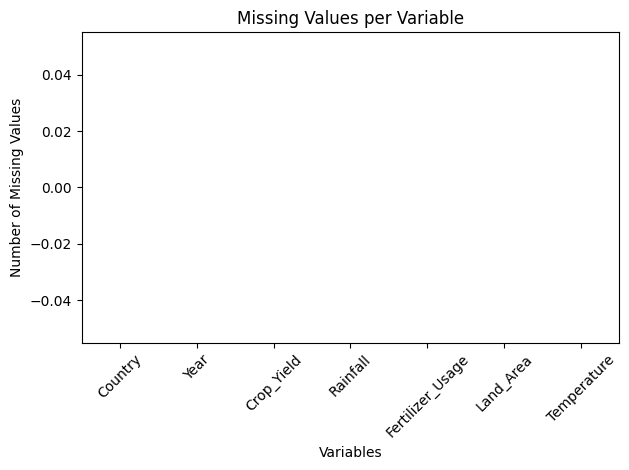

In [19]:
#Missing values bar plot
import matplotlib.pyplot as plt

missing_values["Missing_Count"].plot(kind="bar")
plt.title("Missing Values per Variable")
plt.xlabel("Variables")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

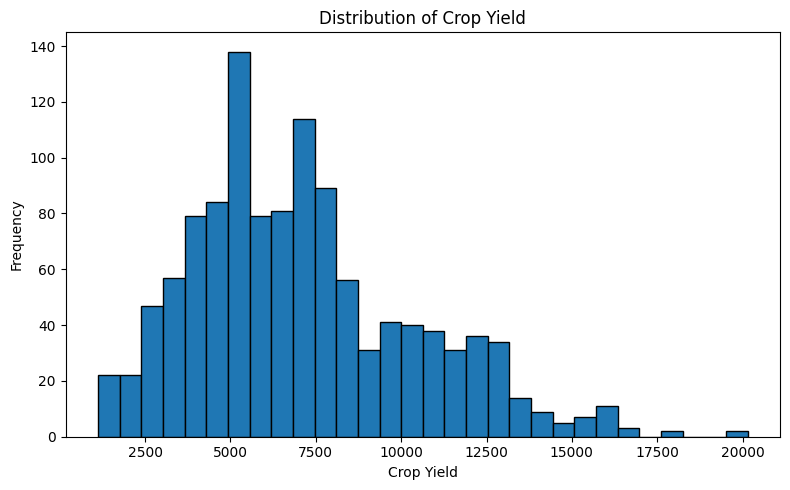

In [20]:
# Histogram of crop yield
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(merged["Crop_Yield"], bins=30, edgecolor="black")
plt.title("Distribution of Crop Yield")
plt.xlabel("Crop Yield")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

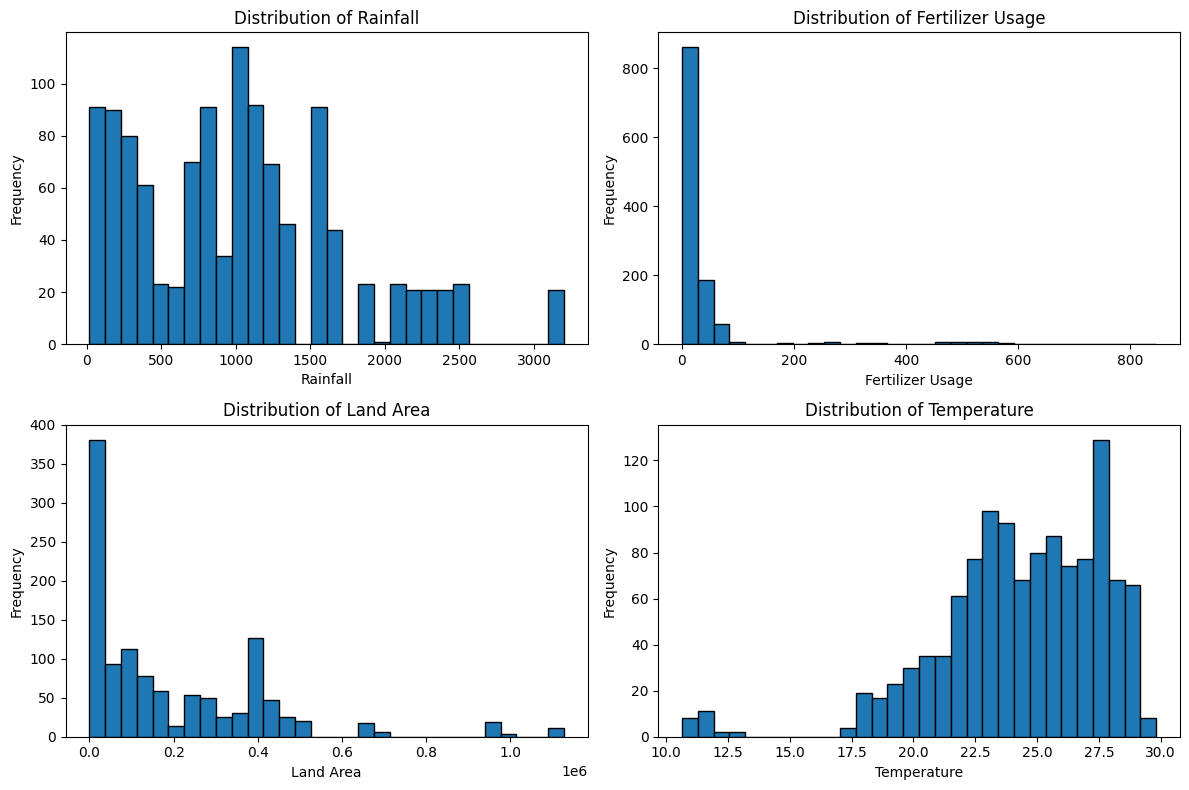

In [21]:
# Histograms of explanatory variables

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].hist(merged["Rainfall"], bins=30, edgecolor="black")
axes[0, 0].set_title("Distribution of Rainfall")
axes[0, 0].set_xlabel("Rainfall")
axes[0, 0].set_ylabel("Frequency")

axes[0, 1].hist(merged["Fertilizer_Usage"], bins=30, edgecolor="black")
axes[0, 1].set_title("Distribution of Fertilizer Usage")
axes[0, 1].set_xlabel("Fertilizer Usage")
axes[0, 1].set_ylabel("Frequency")

axes[1, 0].hist(merged["Land_Area"], bins=30, edgecolor="black")
axes[1, 0].set_title("Distribution of Land Area")
axes[1, 0].set_xlabel("Land Area")
axes[1, 0].set_ylabel("Frequency")

axes[1, 1].hist(merged["Temperature"], bins=30, edgecolor="black")
axes[1, 1].set_title("Distribution of Temperature")
axes[1, 1].set_xlabel("Temperature")
axes[1, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

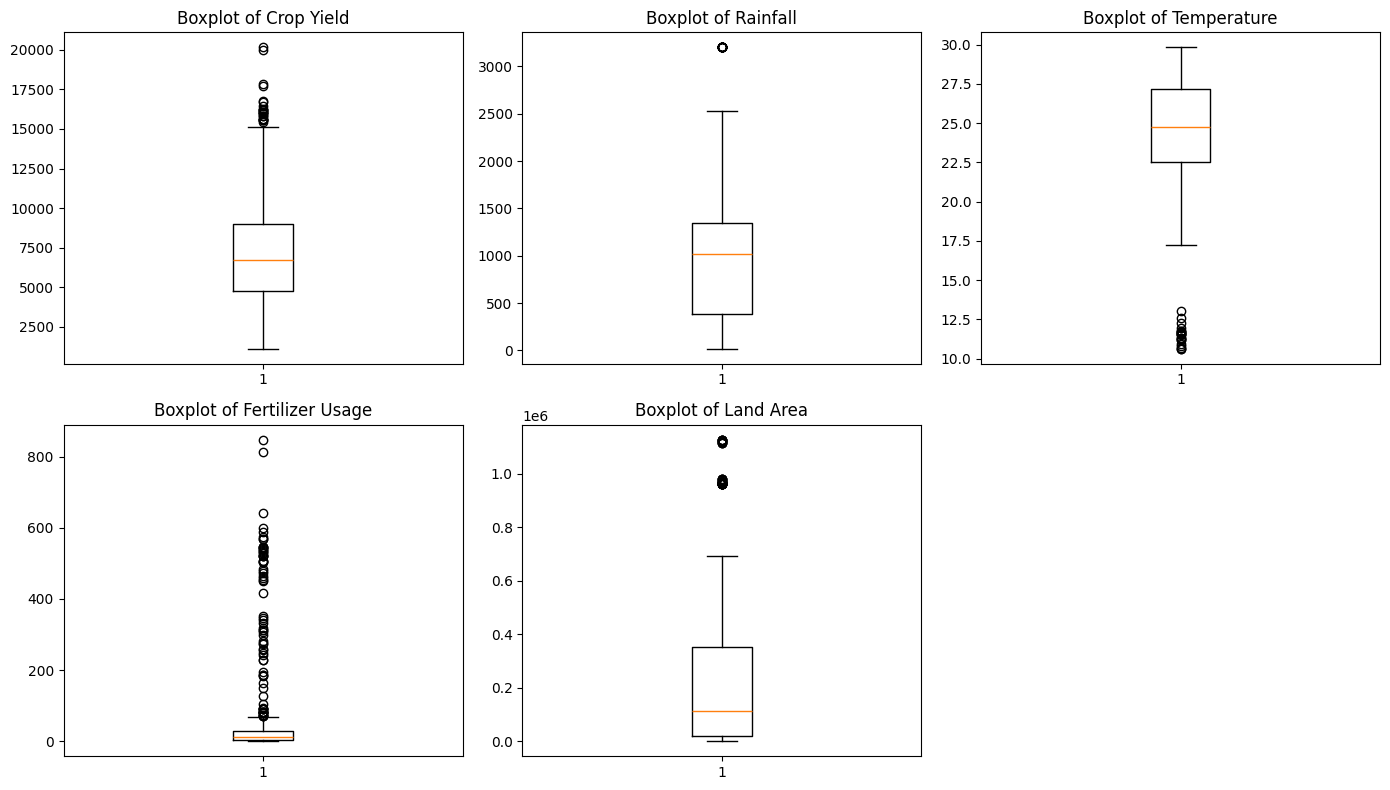

In [22]:
#Outlier detection

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes[0, 0].boxplot(merged["Crop_Yield"])
axes[0, 0].set_title("Boxplot of Crop Yield")

axes[0, 1].boxplot(merged["Rainfall"])
axes[0, 1].set_title("Boxplot of Rainfall")

axes[0, 2].boxplot(merged["Temperature"])
axes[0, 2].set_title("Boxplot of Temperature")

axes[1, 0].boxplot(merged["Fertilizer_Usage"])
axes[1, 0].set_title("Boxplot of Fertilizer Usage")

axes[1, 1].boxplot(merged["Land_Area"])
axes[1, 1].set_title("Boxplot of Land Area")

fig.delaxes(axes[1, 2])

plt.tight_layout()
plt.show()

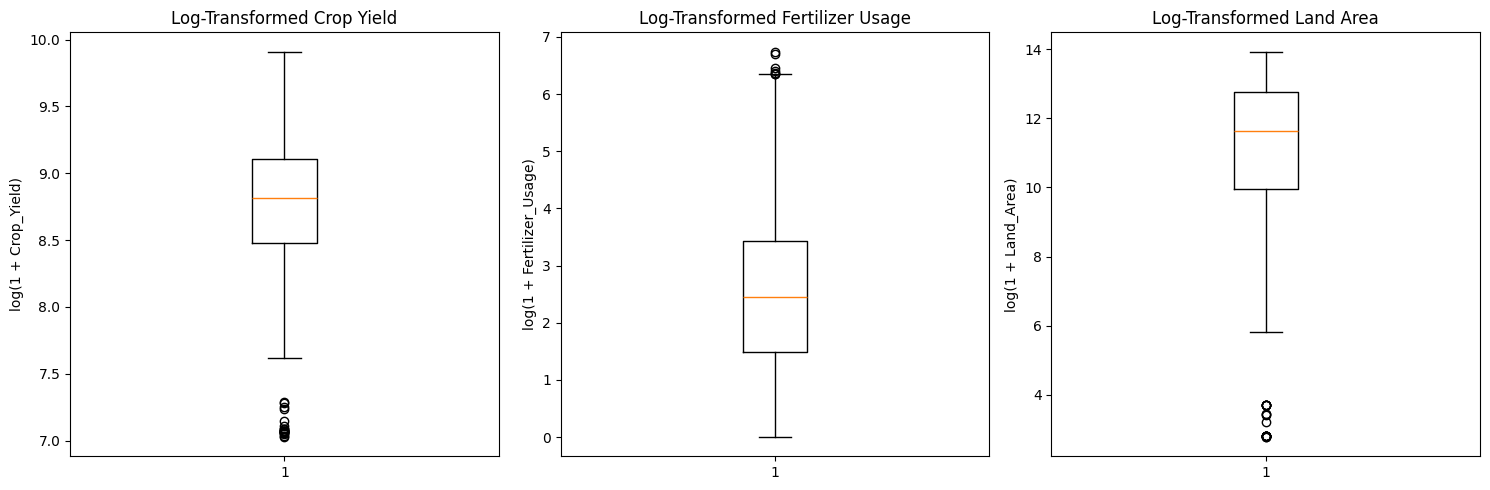

In [23]:
#Log box plot

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].boxplot(np.log1p(merged["Crop_Yield"]))
axes[0].set_title("Log-Transformed Crop Yield")
axes[0].set_ylabel("log(1 + Crop_Yield)")

axes[1].boxplot(np.log1p(merged["Fertilizer_Usage"]))
axes[1].set_title("Log-Transformed Fertilizer Usage")
axes[1].set_ylabel("log(1 + Fertilizer_Usage)")

axes[2].boxplot(np.log1p(merged["Land_Area"]))
axes[2].set_title("Log-Transformed Land Area")
axes[2].set_ylabel("log(1 + Land_Area)")

plt.tight_layout()
plt.show()

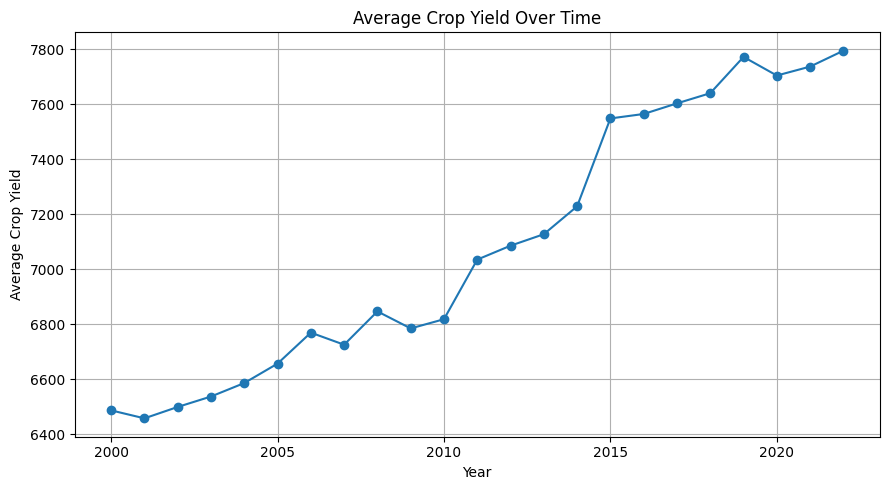

In [24]:
# average crop yield over time

yearly_yield = merged.groupby("Year")["Crop_Yield"].mean()

plt.figure(figsize=(9,5))
plt.plot(yearly_yield.index, yearly_yield.values, marker="o")
plt.title("Average Crop Yield Over Time")
plt.xlabel("Year")
plt.ylabel("Average Crop Yield")
plt.grid(True)
plt.tight_layout()
plt.show()

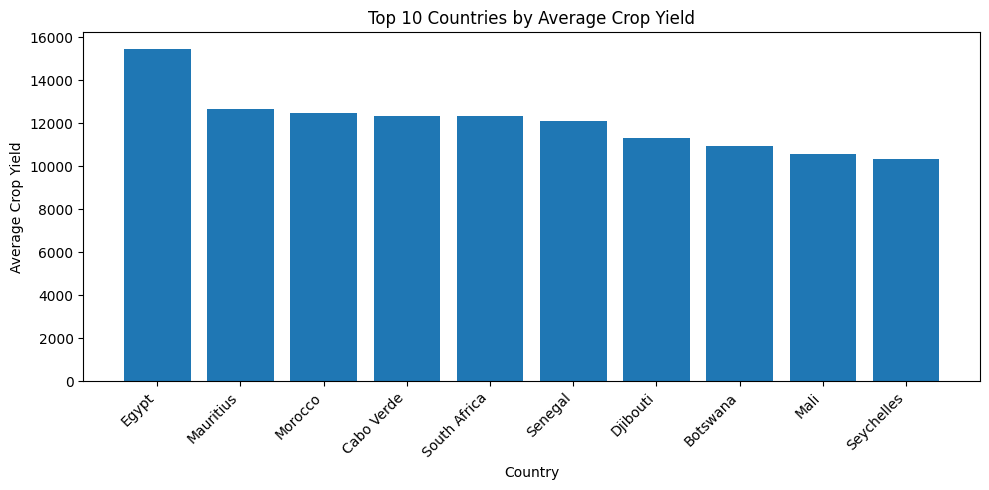

In [25]:
#top 10 countries by average crop yield

top_countries = (
    merged.groupby("Country")["Crop_Yield"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,5))
plt.bar(top_countries.index, top_countries.values)
plt.title("Top 10 Countries by Average Crop Yield")
plt.xlabel("Country")
plt.ylabel("Average Crop Yield")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

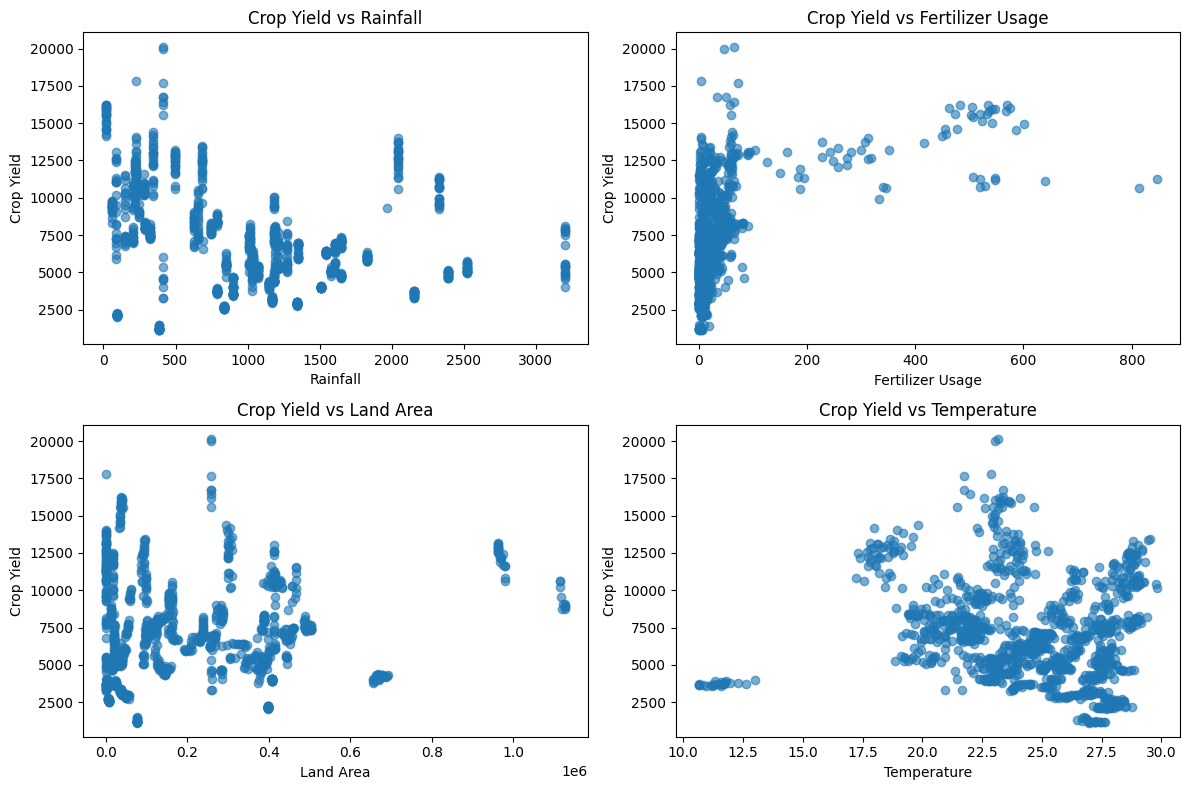

In [26]:
#scatter plots of Crop_Yield against predictors

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].scatter(merged["Rainfall"], merged["Crop_Yield"], alpha=0.6)
axes[0, 0].set_title("Crop Yield vs Rainfall")
axes[0, 0].set_xlabel("Rainfall")
axes[0, 0].set_ylabel("Crop Yield")

axes[0, 1].scatter(merged["Fertilizer_Usage"], merged["Crop_Yield"], alpha=0.6)
axes[0, 1].set_title("Crop Yield vs Fertilizer Usage")
axes[0, 1].set_xlabel("Fertilizer Usage")
axes[0, 1].set_ylabel("Crop Yield")

axes[1, 0].scatter(merged["Land_Area"], merged["Crop_Yield"], alpha=0.6)
axes[1, 0].set_title("Crop Yield vs Land Area")
axes[1, 0].set_xlabel("Land Area")
axes[1, 0].set_ylabel("Crop Yield")

axes[1, 1].scatter(merged["Temperature"], merged["Crop_Yield"], alpha=0.6)
axes[1, 1].set_title("Crop Yield vs Temperature")
axes[1, 1].set_xlabel("Temperature")
axes[1, 1].set_ylabel("Crop Yield")

plt.tight_layout()
plt.show()

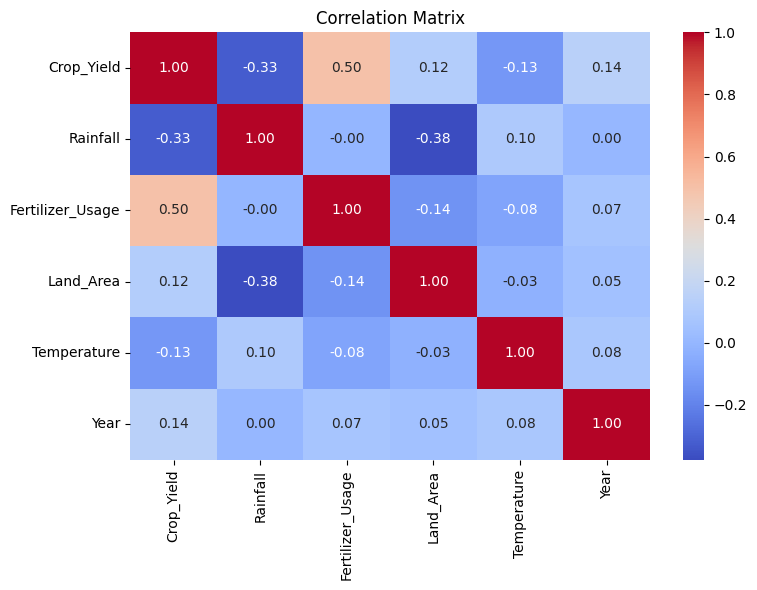

In [27]:
#Correlation matrix

import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = merged[[
    "Crop_Yield",
    "Rainfall",
    "Fertilizer_Usage",
    "Land_Area",
    "Temperature",
    "Year"
]].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

# C3: Comparative sampling exercise

---



In [28]:
#define population size and target sample size
N = len(merged)
n = int(0.3 * N)

print("Population size N =", N)
print("Target sample size n =", n)


Population size N = 1172
Target sample size n = 351


In [29]:
#simple random sampling

sample_random = merged.sample(n=n, random_state=42)

mean_random = sample_random["Crop_Yield"].mean()
var_random = sample_random["Crop_Yield"].var()

print("=== Simple Random Sample ===")
print("Sample size:", len(sample_random))
print("Mean Crop_Yield:", mean_random)
print("Variance Crop_Yield:", var_random)

=== Simple Random Sample ===
Sample size: 351
Mean Crop_Yield: 6992.21549075183
Variance Crop_Yield: 10721944.870248236


In [30]:
#Stratified sampling by country

sample_stratified = (
    merged.groupby("Country", group_keys=False)
    .apply(lambda x: x.sample(frac=0.3, random_state=42))
    .reset_index(drop=True)
)

mean_stratified = sample_stratified["Crop_Yield"].mean()
var_stratified = sample_stratified["Crop_Yield"].var()

print("=== Stratified Sample ===")
print("Sample size:", len(sample_stratified))
print("Mean Crop_Yield:", mean_stratified)
print("Variance Crop_Yield:", var_stratified)

=== Stratified Sample ===
Sample size: 356
Mean Crop_Yield: 6943.312042884974
Variance Crop_Yield: 10083517.929814989


/tmp/ipykernel_7715/3683138810.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(frac=0.3, random_state=42))


In [31]:
sample_stratified = (
    merged.groupby("Country", group_keys=False)
    .apply(lambda x: x.sample(frac=0.3, random_state=42))
    .reset_index(drop=True)
)

mean_stratified = sample_stratified["Crop_Yield"].mean()
var_stratified = sample_stratified["Crop_Yield"].var()

print("=== Stratified Sample ===")
print("Sample size:", len(sample_stratified))
print("Mean Crop_Yield:", mean_stratified)
print("Variance Crop_Yield:", var_stratified)

=== Stratified Sample ===
Sample size: 356
Mean Crop_Yield: 6943.312042884974
Variance Crop_Yield: 10083517.929814989


/tmp/ipykernel_7715/3901527067.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(frac=0.3, random_state=42))


In [32]:
#cluster sampling by country

import numpy as np

countries = merged["Country"].unique()
n_clusters = int(0.3 * len(countries))

np.random.seed(42)
selected_countries = np.random.choice(countries, size=n_clusters, replace=False)

sample_cluster = merged[merged["Country"].isin(selected_countries)].copy()

mean_cluster = sample_cluster["Crop_Yield"].mean()
var_cluster = sample_cluster["Crop_Yield"].var()

print("=== Cluster Sample ===")
print("Selected countries:", selected_countries)
print("Sample size:", len(sample_cluster))
print("Mean Crop_Yield:", mean_cluster)
print("Variance Crop_Yield:", var_cluster)

=== Cluster Sample ===
Selected countries: ['Ethiopia' 'Senegal' 'Togo' "Côte d'Ivoire" 'Sierra Leone' 'Burundi'
 'Eritrea' 'United Republic of Tanzania' 'Botswana' 'Mauritania'
 'Democratic Republic of the Congo' 'Central African Republic' 'Lesotho'
 'Cabo Verde' 'Morocco']
Sample size: 335
Mean Crop_Yield: 6333.19099175748
Variance Crop_Yield: 16005928.61678204


In [33]:
sampling_results = pd.DataFrame({
    "Sampling_Method": ["Simple Random", "Stratified", "Cluster"],
    "Sample_Size": [len(sample_random), len(sample_stratified), len(sample_cluster)],
    "Mean_Crop_Yield": [mean_random, mean_stratified, mean_cluster],
    "Variance_Crop_Yield": [var_random, var_stratified, var_cluster]
})

print(sampling_results)

  Sampling_Method  Sample_Size  Mean_Crop_Yield  Variance_Crop_Yield
0   Simple Random          351      6992.215491         1.072194e+07
1      Stratified          356      6943.312043         1.008352e+07
2         Cluster          335      6333.190992         1.600593e+07


# `C4: Hypothesis testing and power analysis`



---






In [34]:
import numpy as np
from scipy import stats
from statsmodels.stats.power import TTestPower

mu_population = merged["Crop_Yield"].mean()

print("Population size N =", len(merged))
print("Population mean (mu_population) =", mu_population)

Population size N = 1172
Population mean (mu_population) = 7106.494459378266


In [35]:
#sample statistics from the simple random sample

x_bar = sample_random["Crop_Yield"].mean()
s = sample_random["Crop_Yield"].std(ddof=1)
n = len(sample_random)

print("Sample size n =", n)
print("Sample mean (x_bar) =", x_bar)
print("Sample standard deviation (s) =", s)

Sample size n = 351
Sample mean (x_bar) = 6992.21549075183
Sample standard deviation (s) = 3274.43809992619


In [36]:
#one-sample t-test

t_stat = (x_bar - mu_population) / (s / np.sqrt(n))
p_value = 2 * (1 - stats.t.cdf(abs(t_stat), df=n - 1))

alpha = 0.05

print("t-statistic =", t_stat)
print("p-value =", p_value)

if p_value < alpha:
    print("Decision: Reject H0")
    print("Conclusion: The sample mean is significantly different from the population mean.")
else:
    print("Decision: Fail to reject H0")
    print("Conclusion: The sample mean is not significantly different from the population mean.")

t-statistic = -0.6538574636795358
p-value = 0.5136329981231877
Decision: Fail to reject H0
Conclusion: The sample mean is not significantly different from the population mean.


In [37]:
#analytical 95% confidence interval

t_critical = stats.t.ppf(1 - alpha/2, df=n - 1)
margin_error = t_critical * (s / np.sqrt(n))

ci_lower = x_bar - margin_error
ci_upper = x_bar + margin_error

print("95% Confidence Interval = [{:.6f}, {:.6f}]".format(ci_lower, ci_upper))

95% Confidence Interval = [6648.471038, 7335.959944]


In [38]:
#power calculation

effect_shift = 2
effect_size = effect_shift / s

power_analysis = TTestPower()
power_value = power_analysis.power(
    effect_size=effect_size,
    nobs=n,
    alpha=0.05,
    alternative='two-sided'
)

print("Chosen shift in mean =", effect_shift)
print("Effect size (Cohen's d) =", effect_size)
print("Power of the test =", power_value)

Chosen shift in mean = 2
Effect size (Cohen's d) = 0.0006107918180053801
Power of the test = 0.05001491796236755


In [39]:
#sample size for 90% power

n_required = power_analysis.solve_power(
    effect_size=effect_size,
    power=0.90,
    alpha=0.05,
    alternative='two-sided'
)

print("Required sample size for 90% power =", int(np.ceil(n_required)))

Required sample size for 90% power = 28164995


# `C5: Bootstrapping implementation`

---



In [40]:
#response variable

import numpy as np
import matplotlib.pyplot as plt

y = sample_random["Crop_Yield"].values

n = len(y)
x_bar = np.mean(y)
s = np.std(y, ddof=1)

print("Sample size n =", n)
print("Sample mean x_bar =", x_bar)
print("Sample standard deviation s =", s)

Sample size n = 351
Sample mean x_bar = 6992.21549075183
Sample standard deviation s = 3274.4380999261907


In [41]:
#analytical 95% confidence interval

from scipy import stats

alpha = 0.05
t_critical = stats.t.ppf(1 - alpha/2, df=n-1)
margin_error = t_critical * (s / np.sqrt(n))

ci_analytical_lower = x_bar - margin_error
ci_analytical_upper = x_bar + margin_error

print("Analytical 95% CI = [{:.6f}, {:.6f}]".format(ci_analytical_lower, ci_analytical_upper))

Analytical 95% CI = [6648.471038, 7335.959944]


In [42]:
#bootstrap algorithm

B = 10000
rng = np.random.default_rng(42)

bootstrap_means = np.empty(B)

for i in range(B):
    bootstrap_sample = rng.choice(y, size=n, replace=True)
    bootstrap_means[i] = np.mean(bootstrap_sample)

print("Bootstrap completed.")
print("Mean of bootstrap means =", np.mean(bootstrap_means))
print("Bootstrap standard error =", np.std(bootstrap_means, ddof=1))

Bootstrap completed.
Mean of bootstrap means = 6992.872882771032
Bootstrap standard error = 173.1816383748612


In [43]:
#bootstrap 95% confidence interval

ci_boot_lower = np.percentile(bootstrap_means, 2.5)
ci_boot_upper = np.percentile(bootstrap_means, 97.5)

print("Bootstrap 95% CI = [{:.6f}, {:.6f}]".format(ci_boot_lower, ci_boot_upper))

Bootstrap 95% CI = [6658.859223, 7336.717284]


In [44]:
#compare both intervals

print("Analytical CI width =", ci_analytical_upper - ci_analytical_lower)
print("Bootstrap CI width  =", ci_boot_upper - ci_boot_lower)

print("Difference in lower bounds =", abs(ci_boot_lower - ci_analytical_lower))
print("Difference in upper bounds =", abs(ci_boot_upper - ci_analytical_upper))

Analytical CI width = 687.4889055880521
Bootstrap CI width  = 677.8580604722338
Difference in lower bounds = 10.388185479677304
Difference in upper bounds = 0.7573403638589298


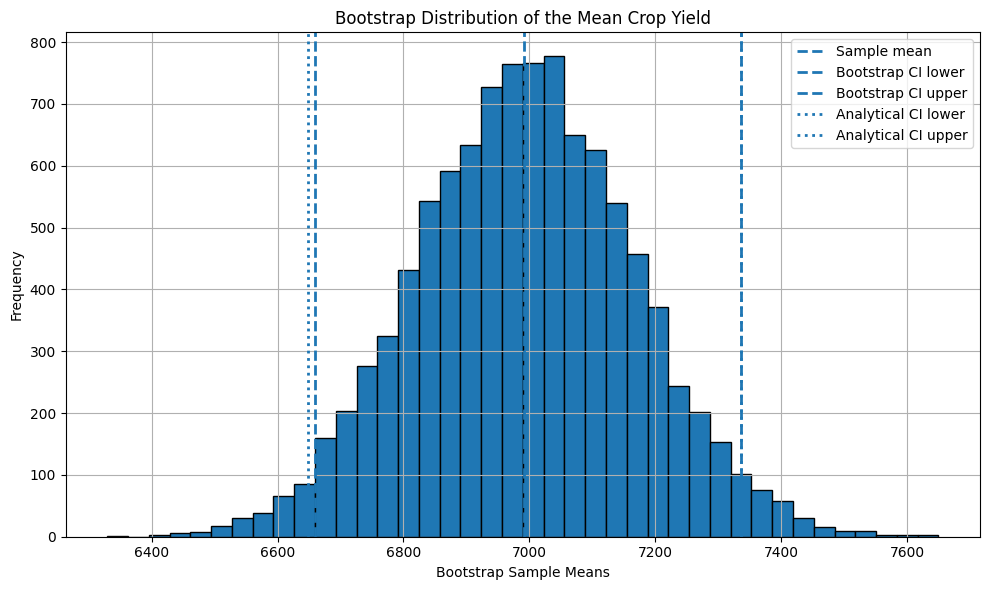

In [45]:
#bootstrap distribution graph

plt.figure(figsize=(10, 6))
plt.hist(bootstrap_means, bins=40, edgecolor='black')

plt.axvline(x_bar, linestyle='--', linewidth=2, label='Sample mean')
plt.axvline(ci_boot_lower, linestyle='--', linewidth=2, label='Bootstrap CI lower')
plt.axvline(ci_boot_upper, linestyle='--', linewidth=2, label='Bootstrap CI upper')
plt.axvline(ci_analytical_lower, linestyle=':', linewidth=2, label='Analytical CI lower')
plt.axvline(ci_analytical_upper, linestyle=':', linewidth=2, label='Analytical CI upper')

plt.title("Bootstrap Distribution of the Mean Crop Yield")
plt.xlabel("Bootstrap Sample Means")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# `Milestone III`

# C1 Modeling specific data preparation


---



In [46]:
#check dataset and keep only needed variables

# Select variables
model_data = merged[[
    "Country",
    "Year",
    "Crop_Yield",
    "Rainfall",
    "Fertilizer_Usage",
    "Land_Area",
    "Temperature"
]].copy()

print("Shape of modeling dataset:", model_data.shape)
print("\nColumns:")
print(model_data.columns.tolist())

print("\nMissing values:")
print(model_data.isnull().sum())

Shape of modeling dataset: (1172, 7)

Columns:
['Country', 'Year', 'Crop_Yield', 'Rainfall', 'Fertilizer_Usage', 'Land_Area', 'Temperature']

Missing values:
Country             0
Year                0
Crop_Yield          0
Rainfall            0
Fertilizer_Usage    0
Land_Area           0
Temperature         0
dtype: int64


In [47]:
# Log-transform the most skewed predictors
import numpy as np

model_data["log_Fertilizer_Usage"] = np.log1p(model_data["Fertilizer_Usage"])
model_data["log_Land_Area"] = np.log1p(model_data["Land_Area"])

print(model_data[[
    "Fertilizer_Usage", "log_Fertilizer_Usage",
    "Land_Area", "log_Land_Area"
]].head())

   Fertilizer_Usage  log_Fertilizer_Usage  Land_Area  log_Land_Area
0         12.046463              2.568517   400210.0      12.899747
1         13.886325              2.700443   401090.0      12.901944
2          9.641579              2.364769   398550.0      12.895591
3          6.001173              1.946078   399057.0      12.896862
4         25.095155              3.261750   411450.0      12.927445


In [48]:
# STEP 1 - TRAIN/TEST SPLIT + CROSS-VALIDATION SETUP

!pip install -q lightgbm catboost

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. Build X and y

X = model_data[[
    "Rainfall",
    "log_Fertilizer_Usage",
    "log_Land_Area",
    "Temperature",
    "Year",
    "Country"
]].copy()

y = model_data["Crop_Yield"].copy()

# 2. Train/test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training size:", X_train.shape)
print("Test size:", X_test.shape)

# 3. Common CV setup

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error"
}

# 4. Common preprocessing

categorical_features = ["Country"]
numeric_features = [
    "Rainfall",
    "log_Fertilizer_Usage",
    "log_Land_Area",
    "Temperature",
    "Year"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]), numeric_features),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.7 MB/s eta 0:00:00
Training size: (937, 6)
Test size: (235, 6)


## C2: Model implementation

---



In [49]:
!pip install xgboost lightgbm catboost

In [50]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

In [51]:
#prepare the dataset for the models

model_data = merged[[
    "Country",
    "Year",
    "Crop_Yield",
    "Rainfall",
    "Fertilizer_Usage",
    "Land_Area",
    "Temperature"
]].copy()

model_data = model_data.dropna()

model_data["log_Fertilizer_Usage"] = np.log1p(model_data["Fertilizer_Usage"])
model_data["log_Land_Area"] = np.log1p(model_data["Land_Area"])

X = model_data[[
    "Country",
    "Year",
    "Rainfall",
    "log_Fertilizer_Usage",
    "log_Land_Area",
    "Temperature"
]]

y = model_data["Crop_Yield"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1172, 6)
y shape: (1172,)


In [52]:
#train\test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training size:", X_train.shape)
print("Test size:", X_test.shape)

Training size: (937, 6)
Test size: (235, 6)


In [53]:
#preprocessing

categorical_features = ["Country"]
numeric_features = [
    "Year",
    "Rainfall",
    "log_Fertilizer_Usage",
    "log_Land_Area",
    "Temperature"
]

preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numeric_features)
    ]
)

preprocessor_tree = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numeric_features)
    ]
)

In [54]:
#defining the models

models = {
    "MLR": Pipeline(steps=[
        ("preprocessor", preprocessor_scaled),
        ("model", LinearRegression())
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor_tree),
        ("model", RandomForestRegressor(
            n_estimators=300,
            random_state=42
        ))
    ]),

    "XGBoost": Pipeline(steps=[
        ("preprocessor", preprocessor_tree),
        ("model", XGBRegressor(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            objective="reg:squarederror"
        ))
    ]),

    "LightGBM": Pipeline(steps=[
        ("preprocessor", preprocessor_tree),
        ("model", LGBMRegressor(
            n_estimators=300,
            learning_rate=0.05,
            random_state=42
        ))
    ]),

    "CatBoost": Pipeline(steps=[
        ("preprocessor", preprocessor_tree),
        ("model", CatBoostRegressor(
            iterations=300,
            learning_rate=0.05,
            depth=6,
            random_state=42,
            verbose=0
        ))
    ])
}

In [55]:
results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    train_mae = mean_absolute_error(y_train, y_train_pred)
    test_mae = mean_absolute_error(y_test, y_test_pred)

    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

    results.append({
        "Model": name,
        "Train R2": train_r2,
        "Test R2": test_r2,
        "Train MAE": train_mae,
        "Test MAE": test_mae,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="Test R2", ascending=False)

results_df

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000487 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 864
[LightGBM] [Info] Number of data points in the train set: 937, number of used features: 17
[LightGBM] [Info] Start training from score 7141.819386


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Model,Train R2,Test R2,Train MAE,Test MAE,Train RMSE,Test RMSE
2,XGBoost,0.983931,0.962838,297.075274,423.476376,417.087396,622.475036
1,Random Forest,0.993099,0.955499,122.167132,314.397691,273.339621,681.176345
4,CatBoost,0.975049,0.947190,378.805086,481.779370,519.740252,742.050463
3,LightGBM,0.992407,0.941895,169.902877,423.342096,286.708029,778.358578
0,MLR,0.913927,0.893784,572.771709,586.811140,965.319228,1052.371037


In [56]:
#cross validation

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error"
}

for name, model in models.items():
    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        return_train_score=False
    )

    cv_results.append({
        "Model": name,
        "CV R2 Mean": scores["test_r2"].mean(),
        "CV R2 Std": scores["test_r2"].std(),
        "CV MAE Mean": -scores["test_mae"].mean(),
        "CV RMSE Mean": -scores["test_rmse"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df = cv_results_df.sort_values(by="CV R2 Mean", ascending=False)

cv_results_df

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000038 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 864
[LightGBM] [Info] Number of data points in the train set: 937, number of used features: 17
[LightGBM] [Info] Start training from score 7141.819386
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000102 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 866
[LightGBM] [Info] Number of data points in the train set: 937, number of used features: 18
[LightGBM] [Info] Start training from score 7094.587578


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000077 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 863
[LightGBM] [Info] Number of data points in the train set: 938, number of used features: 16
[LightGBM] [Info] Start training from score 7143.460641
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000035 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 864
[LightGBM] [Info] Number of data points in the train set: 938, number of used features: 17
[LightGBM] [Info] Start training from score 7080.058984


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000091 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 865
[LightGBM] [Info] Number of data points in the train set: 938, number of used features: 18
[LightGBM] [Info] Start training from score 7072.570709


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Model,CV R2 Mean,CV R2 Std,CV MAE Mean,CV RMSE Mean
4,CatBoost,0.937345,0.027249,503.700759,806.183082
2,XGBoost,0.934070,0.034124,472.473797,814.944221
3,LightGBM,0.931446,0.049299,436.072182,820.775462
1,Random Forest,0.921354,0.060326,349.664649,859.216512
0,MLR,0.899559,0.031568,598.788403,1022.018856


In [57]:
best_model_name = cv_results_df.iloc[0]["Model"]
best_model = models[best_model_name]

print("Best model based on cross-validation R2:", best_model_name)

best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

print("Test R2:", r2_score(y_test, y_pred_best))
print("Test MAE:", mean_absolute_error(y_test, y_pred_best))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_best)))

Best model based on cross-validation R2: CatBoost
Test R2: 0.9471896348937061
Test MAE: 481.77937013926123
Test RMSE: 742.0504625486512


In [58]:
final_model = models["CatBoost"]

final_model.fit(X_train, y_train)

y_train_pred_cat = final_model.predict(X_train)
y_test_pred_cat = final_model.predict(X_test)

catboost_train_r2 = r2_score(y_train, y_train_pred_cat)
catboost_test_r2 = r2_score(y_test, y_test_pred_cat)

catboost_train_mae = mean_absolute_error(y_train, y_train_pred_cat)
catboost_test_mae = mean_absolute_error(y_test, y_test_pred_cat)

catboost_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_cat))
catboost_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_cat))

print("Final selected model: CatBoost")
print("Train R2:", catboost_train_r2)
print("Test R2:", catboost_test_r2)
print("Train MAE:", catboost_train_mae)
print("Test MAE:", catboost_test_mae)
print("Train RMSE:", catboost_train_rmse)
print("Test RMSE:", catboost_test_rmse)

Final selected model: CatBoost
Train R2: 0.9750485646164436
Test R2: 0.9471896348937061
Train MAE: 378.805085546008
Test MAE: 481.77937013926123
Train RMSE: 519.7402515256682
Test RMSE: 742.0504625486512


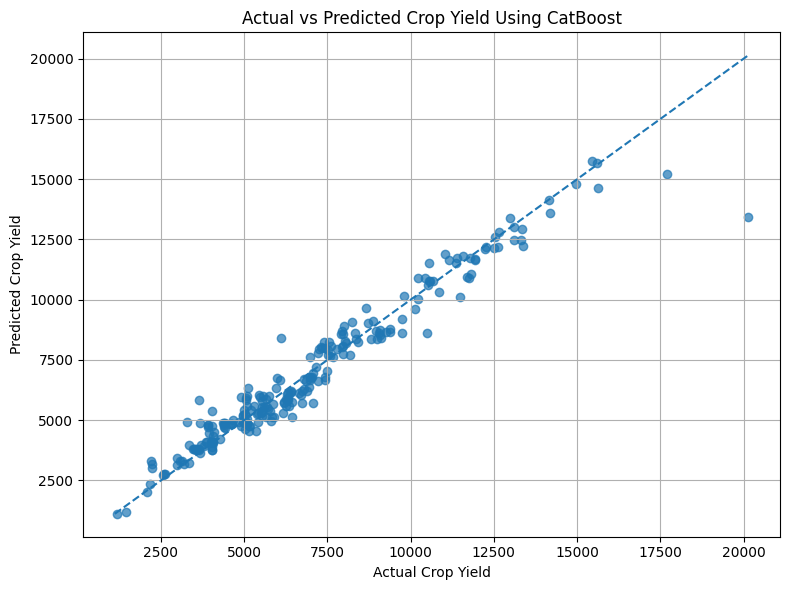

In [59]:
#Actual vs Predicted plot for CatBoost

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred_cat, alpha=0.7)

min_value = min(y_test.min(), y_test_pred_cat.min())
max_value = max(y_test.max(), y_test_pred_cat.max())

plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")

plt.title("Actual vs Predicted Crop Yield Using CatBoost")
plt.xlabel("Actual Crop Yield")
plt.ylabel("Predicted Crop Yield")
plt.grid(True)
plt.tight_layout()

plt.savefig("catboost_actual_vs_predicted.png", dpi=300)
plt.show()

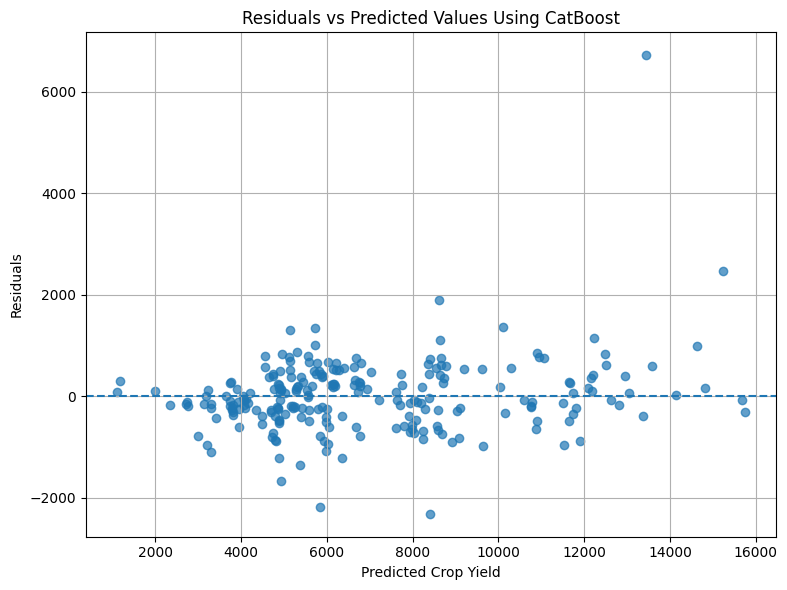

In [60]:
#Residual plot

catboost_residuals = y_test - y_test_pred_cat

plt.figure(figsize=(8, 6))

plt.scatter(y_test_pred_cat, catboost_residuals, alpha=0.7)
plt.axhline(0, linestyle="--")

plt.title("Residuals vs Predicted Values Using CatBoost")
plt.xlabel("Predicted Crop Yield")
plt.ylabel("Residuals")
plt.grid(True)
plt.tight_layout()

plt.savefig("catboost_residuals_plot.png", dpi=300)
plt.show()

In [61]:
#Feature Importance for CatBoost

# Extract fitted preprocessing and model
fitted_preprocessor = final_model.named_steps["preprocessor"]
fitted_catboost = final_model.named_steps["model"]

# Get feature names after preprocessing
encoded_country_features = fitted_preprocessor.named_transformers_["cat"].get_feature_names_out(categorical_features)
all_feature_names = list(encoded_country_features) + numeric_features

# Get feature importance
feature_importance = fitted_catboost.get_feature_importance()

feature_importance_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": feature_importance
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_df.head(15)

,Feature,Importance
54,Rainfall,31.126590
55,log_Fertilizer_Usage,21.303177
56,log_Land_Area,16.545552
57,Temperature,9.786288
17,Country_Eritrea,5.002414
32,Country_Mauritania,4.747058
53,Year,4.493304
3,Country_Botswana,2.062326
41,Country_Senegal,1.527492
6,Country_Cabo Verde,0.495688


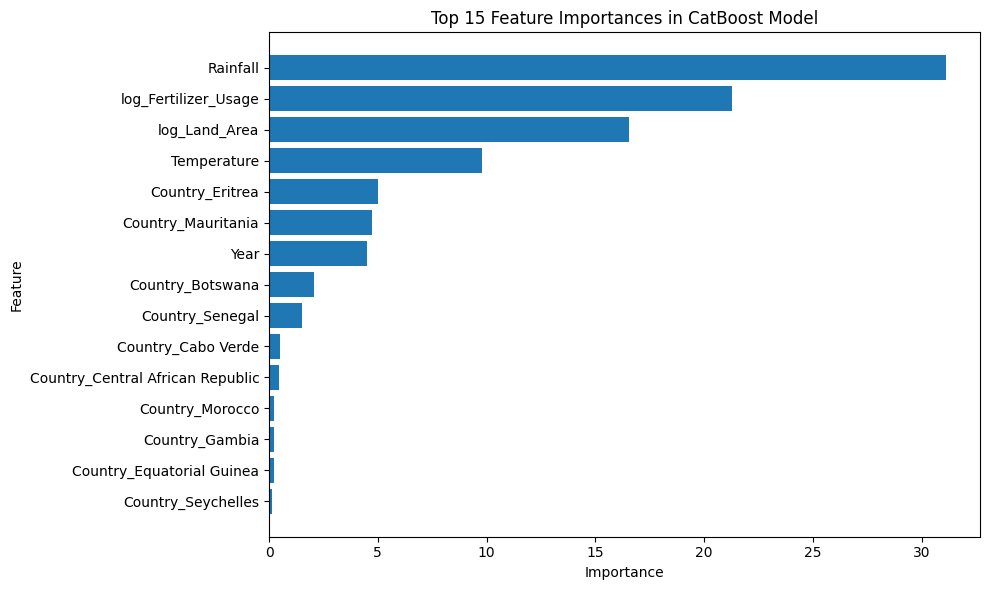

In [62]:
#feature Importance plot

top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(top_features["Feature"], top_features["Importance"])
plt.gca().invert_yaxis()

plt.title("Top 15 Feature Importances in CatBoost Model")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig("catboost_feature_importance.png", dpi=300)
plt.show()

In [63]:
results_df.to_csv("train_test_model_comparison.csv", index=False)
cv_results_df.to_csv("cross_validation_model_comparison.csv", index=False)
feature_importance_df.to_csv("catboost_feature_importance.csv", index=False)

print("Tables saved successfully.")

Tables saved successfully.


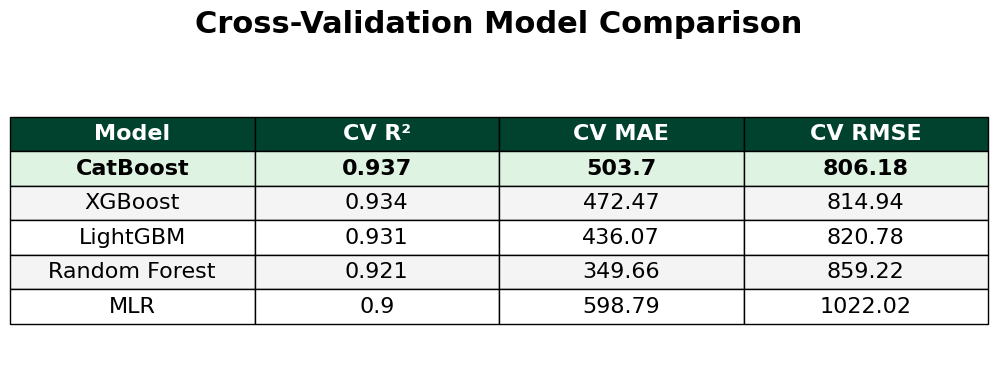

In [64]:
#Cleaner vross validation table for the slides

import pandas as pd
import matplotlib.pyplot as plt

# Clean rounded comparison table
data = {
    "Model": ["CatBoost", "XGBoost", "LightGBM", "Random Forest", "MLR"],
    "CV R²": [0.937, 0.934, 0.931, 0.921, 0.900],
    "CV MAE": [503.70, 472.47, 436.07, 349.66, 598.79],
    "CV RMSE": [806.18, 814.94, 820.78, 859.22, 1022.02]
}

df = pd.DataFrame(data)

fig, ax = plt.subplots(figsize=(10, 4))
ax.axis("off")

table = ax.table(
    cellText=df.values,
    colLabels=df.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(16)
table.scale(1.2, 2)

# Header styling
for col in range(len(df.columns)):
    table[(0, col)].set_text_props(weight="bold", color="white")
    table[(0, col)].set_facecolor("#00422E")

# Highlight CatBoost row
for col in range(len(df.columns)):
    table[(1, col)].set_text_props(weight="bold")
    table[(1, col)].set_facecolor("#DFF3E3")

# Alternating row background
for row in range(2, len(df) + 1):
    for col in range(len(df.columns)):
        if row % 2 == 0:
            table[(row, col)].set_facecolor("#F4F4F4")
        else:
            table[(row, col)].set_facecolor("#FFFFFF")

plt.title(
    "Cross-Validation Model Comparison",
    fontsize=22,
    weight="bold",
    pad=20
)

plt.tight_layout()
plt.savefig("clean_model_comparison_table.png", dpi=300, bbox_inches="tight")
plt.show()

In [66]:
# ============================================================
# C4 - CatBoost statistical inference support
# Feature importance + permutation importance
# Works with your notebook variables
# ============================================================

import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1) Use the fitted CatBoost pipeline
cat_model = final_model

# 2) CatBoost feature importance from the fitted CatBoost estimator
fitted_preprocessor = cat_model.named_steps["preprocessor"]
fitted_catboost = cat_model.named_steps["model"]

# Get feature names after preprocessing
encoded_country_features = fitted_preprocessor.named_transformers_["cat"].get_feature_names_out(categorical_features)
all_feature_names = list(encoded_country_features) + numeric_features

feature_importance = fitted_catboost.get_feature_importance()

fi_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Feature_Importance": feature_importance
}).sort_values(by="Feature_Importance", ascending=False)

print("========== CATBOOST FEATURE IMPORTANCE ==========")
print(fi_df.head(20))

# 3) Permutation importance on test set
# This works directly on the full pipeline using original X_test columns
perm = permutation_importance(
    cat_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="r2"
)

perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_R2_Decrease": perm.importances_mean,
    "Std_R2_Decrease": perm.importances_std
}).sort_values(by="Mean_R2_Decrease", ascending=False)

# 4) Approximate 95% confidence interval for permutation importance
perm_df["CI_Lower"] = perm_df["Mean_R2_Decrease"] - 1.96 * perm_df["Std_R2_Decrease"]
perm_df["CI_Upper"] = perm_df["Mean_R2_Decrease"] + 1.96 * perm_df["Std_R2_Decrease"]

print("\n========== PERMUTATION IMPORTANCE WITH 95% CI ==========")
print(perm_df)

# 5) Final test prediction metrics
y_pred = cat_model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\n========== CATBOOST TEST PERFORMANCE ==========")
print("Test R²:", round(r2, 4))
print("Test MAE:", round(mae, 2))
print("Test RMSE:", round(rmse, 2))

========== CATBOOST FEATURE IMPORTANCE ==========
                             Feature  Feature_Importance
54                          Rainfall           31.126590
55              log_Fertilizer_Usage           21.303177
56                     log_Land_Area           16.545552
57                       Temperature            9.786288
17                   Country_Eritrea            5.002414
32                Country_Mauritania            4.747058
53                              Year            4.493304
3                   Country_Botswana            2.062326
41                   Country_Senegal            1.527492
6                 Country_Cabo Verde            0.495688
8   Country_Central African Republic            0.444405
34                   Country_Morocco            0.242622
21                    Country_Gambia            0.213025
16         Country_Equatorial Guinea            0.210994
42                Country_Seychelles            0.159364
11                     Country_Congo  

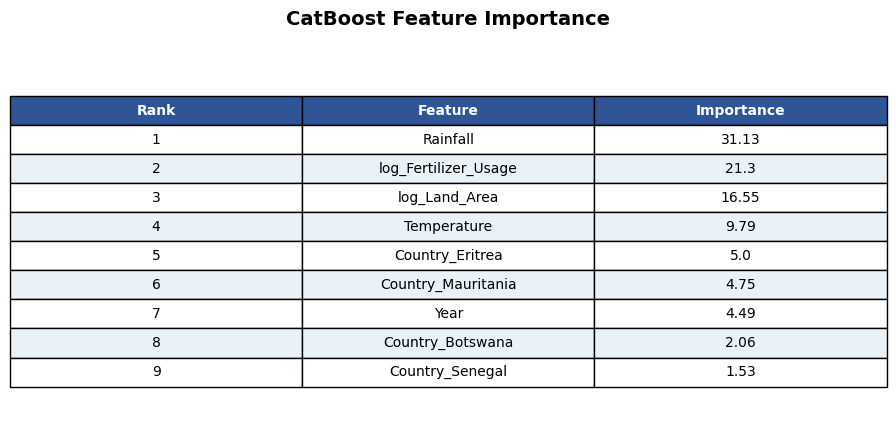

Saved as catboost_feature_importance_table.png


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# CatBoost Feature Importance - Clean Report Table
# ============================================================

# Replace these values with your exact feature importance output if needed
feature_importance_data = {
    "Feature": [
        "Rainfall",
        "log_Fertilizer_Usage",
        "log_Land_Area",
        "Temperature",
        "Country_Eritrea",
        "Country_Mauritania",
        "Year",
        "Country_Botswana",
        "Country_Senegal"
    ],
    "Importance": [
        31.13,
        21.30,
        16.55,
        9.79,
        5.00,
        4.75,
        4.49,
        2.06,
        1.53
    ]
}

fi_table = pd.DataFrame(feature_importance_data)

# Sort from most important to least important
fi_table = fi_table.sort_values(by="Importance", ascending=False).reset_index(drop=True)

# Add rank column
fi_table.insert(0, "Rank", range(1, len(fi_table) + 1))

# Round importance values
fi_table["Importance"] = fi_table["Importance"].round(2)

# Create figure
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axis("off")

# Create table
table = ax.table(
    cellText=fi_table.values,
    colLabels=fi_table.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

# Styling
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.6)

# Header styling
for col in range(len(fi_table.columns)):
    cell = table[0, col]
    cell.set_text_props(weight="bold", color="white")
    cell.set_facecolor("#2F5597")

# Row styling
for row in range(1, len(fi_table) + 1):
    for col in range(len(fi_table.columns)):
        cell = table[row, col]
        if row % 2 == 0:
            cell.set_facecolor("#EAF2F8")
        else:
            cell.set_facecolor("#FFFFFF")

# Title
plt.title(
    "CatBoost Feature Importance",
    fontsize=14,
    fontweight="bold",
    pad=20
)

# Save image
plt.tight_layout()
plt.savefig("catboost_feature_importance_table.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved as catboost_feature_importance_table.png")

In [67]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Train predictions
y_train_pred = final_model.predict(X_train)

train_r2 = r2_score(y_train, y_train_pred)
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

# Test predictions
y_test_pred = final_model.predict(X_test)

test_r2 = r2_score(y_test, y_test_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print("========== CATBOOST TRAIN PERFORMANCE ==========")
print("Train R²:", round(train_r2, 4))
print("Train MAE:", round(train_mae, 2))
print("Train RMSE:", round(train_rmse, 2))

print("\n========== CATBOOST TEST PERFORMANCE ==========")
print("Test R²:", round(test_r2, 4))
print("Test MAE:", round(test_mae, 2))
print("Test RMSE:", round(test_rmse, 2))

========== CATBOOST TRAIN PERFORMANCE ==========
Train R²: 0.975
Train MAE: 378.81
Train RMSE: 519.74

========== CATBOOST TEST PERFORMANCE ==========
Test R²: 0.9472
Test MAE: 481.78
Test RMSE: 742.05


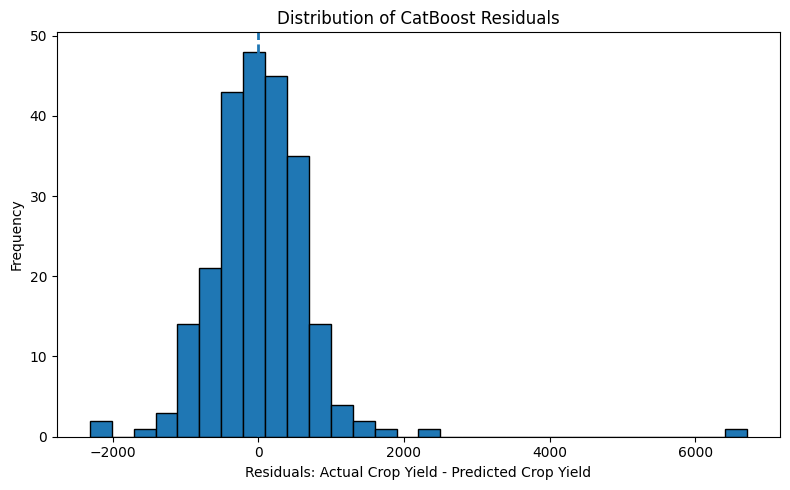

In [68]:
import matplotlib.pyplot as plt
import numpy as np

# Predictions and residuals
y_test_pred = final_model.predict(X_test)
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=30, edgecolor="black")
plt.axvline(0, linestyle="--", linewidth=2)
plt.title("Distribution of CatBoost Residuals")
plt.xlabel("Residuals: Actual Crop Yield - Predicted Crop Yield")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("catboost_residual_distribution.png", dpi=300)
plt.show()

In [69]:
import pandas as pd
import numpy as np

# Predictions
y_test_pred = final_model.predict(X_test)

# Build prediction error dataframe
pred_analysis = X_test.copy()
pred_analysis["Actual_Crop_Yield"] = y_test.values
pred_analysis["Predicted_Crop_Yield"] = y_test_pred
pred_analysis["Residual"] = pred_analysis["Actual_Crop_Yield"] - pred_analysis["Predicted_Crop_Yield"]
pred_analysis["Absolute_Error"] = np.abs(pred_analysis["Residual"])

# Best predicted cases
best_cases = pred_analysis.sort_values("Absolute_Error", ascending=True).head(5)

# Worst predicted cases
worst_cases = pred_analysis.sort_values("Absolute_Error", ascending=False).head(5)

print("========== BEST PREDICTED CASES ==========")
print(best_cases)

print("\n========== WORST PREDICTED CASES ==========")
print(worst_cases)

========== BEST PREDICTED CASES ==========
         Country  Year  Rainfall  log_Fertilizer_Usage  log_Land_Area  \
1039        Togo  2005    1168.0              0.253562      10.468830   
590      Lesotho  2009     788.0              1.359828      10.060107   
423     Ethiopia  2002     848.0              2.891065      12.628005   
654   Madagascar  2006    1513.0              1.260259      12.921302   
332        Egypt  2000      18.1              6.110898      10.401562   

      Temperature  Actual_Crop_Yield  Predicted_Crop_Yield   Residual  \
1039        26.92        3186.320588           3179.512830   6.807759   
590         11.18        3667.277778           3657.722809   9.554969   
423         23.41        5536.885075           5549.699557 -12.814483   
654         22.84        4066.868571           4053.799827  13.068744   
332         22.29       14152.989333          14133.036444  19.952890   

      Absolute_Error  
1039        6.807759  
590         9.554969  
423       